# Holdings pipeline

Builds the 13F holdings table step by step: CSV files → `input_1.holdings_input_table` →
`clean_up_1.holdings_clean`. Every block shows the database feedback (status message, affected rows,
duration, result set) and is written to the run log `logs/holdings/<RUN_ID>/`, so runs can be compared
later (section 7). Execution and logging code lives in `src/pipeline_helpers.py`.

| Section | Phase label | What happens |
|---|---|---|
| 0.2 Database connection | `connection` | read-only check, then working connection |
| 1.1 Create input table | `input_create` | input table and CUSIP check-digit function |
| 1.2 Load CSV files | `input_load` | `load_holdings.py` |
| 1.3 Raw load profile | `input_profile` | row count, size, CUSIP lengths |
| 1.4 Clean CUSIPs | `input_clean` | drop bad `cusip8`, complete `cusip9`, make table durable |
| 1.5 Input indexes and checks | `input_final` | indexes, statistics, checks |
| 2. Clean table | `clean_create` | typed table, rows that pass the basic filters, option rows removed |
| 3. Filings and amendments | `filings` | notices, amendment types, superseded filings |
| 4. Value corrections | `value_fix` | values reported in dollars, SH/PRN, deviation |
| 4.4 Deviation check | `deviation_check` | deviation distribution |
| 5. Ownership | `ownership` | ownership share and outliers |
| 6. Finalise | `clean_final` | indexes, `VACUUM ANALYZE` |

> **The cells modify the database** (DROP / DELETE / UPDATE). Each block is committed as soon as it finishes.

## 0. Setup

### 0.1 Configuration

Paths, table names, connection string and run options:
* `RESET_TRACKING`: `True` makes the loader reload every CSV file (see 1.2)
* `exact_counts`: `True` uses `count(*)` instead of the fast `pg_class` estimate

In [3]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "config")]

from pipeline_helpers import (Loader, PipelineRun, compare_runs, expected_mismatches,
                              load_logs, phase_durations, steps_table)
from local_config import DSN   # machine-specific

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SRC_DIR  = ROOT / "src"                       # load_holdings.py
LOG_ROOT = ROOT / "logs" / "holdings"

INPUT_TABLE = "input_1.holdings_input_table"
CLEAN_TABLE = "clean_up_1.holdings_clean"
AMENDMENT_TABLE = "input_1.final_amendment_types"
FILINGS_TABLE   = "clean_up_1.filings"

# Output of Database/amendments (built from INPUT_TABLE's 13F-HR/A filings)
AMENDMENTS_CSV = ROOT.parent / "amendments" / "data" / "final_amendment_types.csv"

RESET_TRACKING = False   # True = archive tracking.csv so the loader reloads ALL files

p = PipelineRun(LOG_ROOT, dsn=DSN, max_rows=1000, exact_counts=False)
print("RUN_ID :", p.run_id)
print("LOG_DIR:", p.log_dir)

RUN_ID : 20261029_150051
LOG_DIR: <THESIS_DIR>/src/Clean_solution/Database/Initialisation/logs/holdings/20261029_150051


### 0.2 Database connection

First a read-only check on a separate connection (`READ ONLY` transaction, rolled back): server, database,
user, schemas and privileges, current state of the input and clean tables. The working connection
(autocommit) is opened only if the check passes.

In [2]:
CONNECTION_OK = p.check_connection(DSN, schemas=["input_1", "clean_up_1"],
                                   tables=[INPUT_TABLE, CLEAN_TABLE])

✅ **[connection] connection_check_server**: `ok` | 0.1s

> READ ONLY transaction, rolled back. Nothing committed.

,server_version,database,db_user,is_standby,txn_read_only,db_size,other_sessions
0,PostgreSQL 16.15 (Ubuntu 16.15-0ubuntu0.24.04....,Holdings_v2,postgres,False,on,70 GB,0


✅ **[connection] connection_check_schemas**: `ok`

,schema_name,schema_exists,can_create,can_use
0,input_1,True,True,True
1,clean_up_1,True,True,True


✅ **[connection] connection_check_tables**: `ok`

> Existing tables will be dropped and recreated by the pipeline.

,table_name,exists,unlogged,est_rows,total_size
0,input_1.holdings_input_table,True,False,124643104,27 GB
1,clean_up_1.holdings_clean,True,False,101581072,25 GB


In [3]:
assert CONNECTION_OK, "Connection check failed, see connection_check_server above"
p.connect(DSN)

Connected: user=postgres password=xxx dbname=Holdings_v2 host=localhost port=5432


## 1. Input table

`input_1.holdings_input_table` receives every row extracted from the CSV files, before any transformation.
Column names follow the source files.

### 1.1 Create the table and the CUSIP check-digit function

The table is `UNLOGGED` (no WAL) for a fast load and becomes durable in 1.4. `cusip_check_digit()`
computes the 9th CUSIP character from the first 8; it is used in 1.4.

In [4]:
pre = p.stage("input_create")

pre.run("drop_input_table", f"DROP TABLE IF EXISTS {INPUT_TABLE};")

✅ **[input_create] drop_input_table**: `ok` | `DROP TABLE` | 0.1s

""


In [5]:
pre.run("create_input_table", f"""
    -- UNLOGGED = much faster load (no WAL). No indexes / PKs yet.
    CREATE UNLOGGED TABLE {INPUT_TABLE} (
        cusip8                 text,
        "nameOfIssuer"         text,
        "titleOfClass"         text,
        value                  double precision,
        "shrsOrPrnAmt"         text,
        "investmentDiscretion" text,
        "votingAuthority"      text,
        "putCall"              text,
        cusip9                 text,
        shares                 double precision,
        permno                 bigint,
        prc                    double precision,
        shrout                 double precision,
        split                  text,
        deviation              double precision,
        rdate                  bigint,
        fdate                  bigint,
        cik                    bigint,
        form                   text,
        type                   text,
        address                text
    );
""")

✅ **[input_create] create_input_table**: `ok` | `CREATE TABLE` | 0.0s

""


In [6]:
pre.run("create_cusip_check_digit", r"""
    -- CUSIP check digit (9th character) computed from cusip8.
    -- Returns NULL if cusip8 is NULL or not 8 valid characters.
    CREATE OR REPLACE FUNCTION input_1.cusip_check_digit(c8 text)
    RETURNS text
    LANGUAGE sql IMMUTABLE STRICT PARALLEL SAFE AS $$
      SELECT CASE WHEN c8 ~ '^[0-9A-Za-z*@#]{8}$' THEN
        ((10 - sum(v / 10 + v % 10) % 10) % 10)::text
      END
      FROM (
        SELECT CASE WHEN i % 2 = 0 THEN 2 * val ELSE val END AS v
        FROM (
          SELECT i,
                 CASE WHEN ch ~ '[0-9]'    THEN ch::int
                      WHEN ch ~ '[A-Za-z]' THEN ascii(upper(ch)) - 55
                      WHEN ch = '*' THEN 36
                      WHEN ch = '@' THEN 37
                      ELSE 38 END AS val
          FROM (SELECT i, substr(c8, i, 1) AS ch FROM generate_series(1, 8) i) s
        ) t
      ) d
    $$;
""")

✅ **[input_create] create_cusip_check_digit**: `ok` | `CREATE FUNCTION` | 0.0s

""


### 1.2 Load the CSV files

`src/load_holdings.py` runs as a subprocess and copies the files into the input table.

* **Pause:** interrupt the kernel (■). The loader's `PAUSE` file is created and the running batches finish.
  Re-run the cell to resume.
* **Fresh load:** `tracking.csv` marks files as `done`. After dropping the table, set `RESET_TRACKING = True`,
  otherwise every file is skipped. The old tracking file is copied into the run log.

In [7]:
loader = Loader(p.stage("input_load"), SRC_DIR)

loader.preflight()
loader.tracking_summary("before_load")

✅ **[input_load] preflight_paths**: `ok`

,check,path,exists
0,loader BASE_DIR,/src/Clean_solution...,True
1,addresses file,/src/Clean_solution...,True
2,tracking file,/src/Clean_solution...,True
3,csv sample,...,True
4,csv sample,...,True
5,csv sample,...,True
6,csv sample,...,True
7,csv sample,...,True


✅ **[input_load] before_load_tracking_status**: `ok` | rows: **308,593**

,status,files
0,done,305834
1,error,2759


✅ **[input_load] before_load_tracking_errors**: `ok` | rows: **2,759**

,error,files
0,no valid rows,2759


In [8]:
if RESET_TRACKING:
    loader.reset_tracking()

loader.run()

✅ **[input_load] reset_tracking**: `ok`

> tracking.csv moved to tracking_before_reset.csv


Tracking file created with 308,593 entries.

308,593 files pending out of 308,593 total (15,430 batches)
100%|██████████| 15430/15430 [14:45<00:00, 17.42it/s] 
Run complete.

status

done     305834

error      2759

Name: count, dtype: int64


✅ **[input_load] load_holdings_py**: `ok` | 889.5s

> Loader summary:

```
Tracking file created with 308,593 entries.
308,593 files pending out of 308,593 total (15,430 batches)
Run complete.
status
done     305834
error      2759
Name: count, dtype: int64
```

In [9]:
loader.tracking_summary("after_load")   # Status.md (previous run): done 305,834 | error 2,759

✅ **[input_load] after_load_tracking_status**: `ok` | rows: **308,593**

,status,files
0,done,305834
1,error,2759


✅ **[input_load] after_load_tracking_errors**: `ok` | rows: **2,759**

,error,files
0,no valid rows,2759


### 1.3 Profile of the raw load

In [10]:
profile = p.stage("input_profile")

profile.row_estimate(INPUT_TABLE, "raw")          # Status.md: ~124,645,888
profile.table_size(INPUT_TABLE, "raw")

✅ **[input_profile] raw_count_estimate**: `ok` | `SELECT 1` | rows: **1** | 0.0s

,estimate
0,59502380


✅ **[input_profile] raw_size**: `ok` | `SELECT 1` | rows: **1** | 0.0s

,total,heap,indexes
0,25 GB,25 GB,0 bytes


,total,heap,indexes
0,25 GB,25 GB,0 bytes


In [11]:
profile.run("raw_cusip_lengths", f"""
    SELECT count(*) FILTER (WHERE length(cusip9) = 8)                          AS cusip9_len8,
           count(*) FILTER (WHERE length(cusip9) <> 9)                         AS cusip9_not9,
           count(*) FILTER (WHERE cusip9 IS NULL)                              AS cusip9_null,
           count(*) FILTER (WHERE length(cusip8) <> 8)                         AS cusip8_not8,
           count(*) FILTER (WHERE length(cusip8) = 9)                          AS cusip8_len9,
           count(*) FILTER (WHERE length(cusip9) <> 9 AND length(cusip8) <> 8) AS both_bad
    FROM {INPUT_TABLE};
""", note="Status.md: cusip9_len8 3,803,094 | cusip9_not9 3,912,860 | cusip8_not8 109,766 | cusip8_len9 0 | both_bad 109,766")

✅ **[input_profile] raw_cusip_lengths**: `ok` | `SELECT 1` | rows: **1** | 357.1s

> Status.md: cusip9_len8 3,803,094 | cusip9_not9 3,912,860 | cusip8_not8 109,766 | cusip8_len9 0 | both_bad 109,766

,cusip9_len8,cusip9_not9,cusip9_null,cusip8_not8,cusip8_len9,both_bad
0,3803094,3912860,0,109766,0,109766


,cusip9_len8,cusip9_not9,cusip9_null,cusip8_not8,cusip8_len9,both_bad
0,3803094,3912860,0,109766,0,109766


### 1.4 Clean CUSIPs

1. delete rows whose `cusip8` is not 8 characters long
2. append the check digit to `cusip9` values that have only 8 characters
3. `SET LOGGED`: makes the table durable; the rewrite also removes the dead rows left by steps 1–2

In [12]:
inp_clean = p.stage("input_clean")

inp_clean.run("delete_bad_cusip8", f"""
    DELETE FROM {INPUT_TABLE}
    WHERE length(cusip8) <> 8;
""", expected=109_766)

✅ **[input_clean] delete_bad_cusip8**: `ok` | `DELETE 109766` | rows: **109,766** | expected: 109,766 (diff +0) | 179.0s

""


In [13]:
inp_clean.run("complete_cusip9", f"""
    -- cusip9 that is only 8 characters long gets its check digit appended
    UPDATE {INPUT_TABLE}
    SET cusip9 = cusip9 || input_1.cusip_check_digit(cusip9)
    WHERE length(cusip9) = 8
      AND input_1.cusip_check_digit(cusip9) IS NOT NULL;
""", expected=3_803_090, note="Status.md: 4 rows have no valid check digit")

✅ **[input_clean] complete_cusip9**: `ok` | `UPDATE 3803090` | rows: **3,803,090** | expected: 3,803,090 (diff +0) | 195.7s

> Status.md: 4 rows have no valid check digit

""


In [14]:
inp_clean.run("set_logged", f"""
    -- Rewrites the table, so dead tuples from the UPDATE/DELETE disappear (no VACUUM FULL needed).
    ALTER TABLE {INPUT_TABLE} SET LOGGED;
""")

✅ **[input_clean] set_logged**: `ok` | `ALTER TABLE` | 932.2s

""


### 1.5 Indexes, statistics and checks

In [15]:
inp_final = p.stage("input_final")

inp_final.run("idx_input_cusip9",       f"CREATE INDEX ON {INPUT_TABLE} (cusip9);")
inp_final.run("idx_input_cik_rdate",    f"CREATE INDEX ON {INPUT_TABLE} (cik, rdate);")
inp_final.run("idx_input_permno_rdate", f"CREATE INDEX ON {INPUT_TABLE} (permno, rdate);")
inp_final.run("analyze_input",          f"ANALYZE {INPUT_TABLE};")

✅ **[input_final] idx_input_cusip9**: `ok` | `CREATE INDEX` | 665.3s

✅ **[input_final] idx_input_cik_rdate**: `ok` | `CREATE INDEX` | 206.6s

✅ **[input_final] idx_input_permno_rdate**: `ok` | `CREATE INDEX` | 214.8s

✅ **[input_final] analyze_input**: `ok` | `ANALYZE` | 1.6s

""


In [16]:
inp_final.row_estimate(INPUT_TABLE, "input_final")   # Status.md: 124,625,769
inp_final.table_size(INPUT_TABLE, "input_final")

inp_final.run("check_cusip9", f"""
    SELECT count(*) FILTER (WHERE cusip9 IS NULL)      AS cusip9_null,
           count(*) FILTER (WHERE length(cusip9) <> 9) AS cusip9_not9,
           count(DISTINCT cusip9)                      AS distinct_cusip9,
           count(*) FILTER (WHERE prc IS NULL)         AS prc_null
    FROM {INPUT_TABLE};
""", note="Status.md: distinct_cusip9 181,941 | prc_null 4,268,841")

✅ **[input_final] input_final_count_estimate**: `ok` | `SELECT 1` | rows: **1** | 0.0s

,estimate
0,124580224


✅ **[input_final] input_final_size**: `ok` | `SELECT 1` | rows: **1** | 0.0s

,total,heap,indexes
0,28 GB,25 GB,2580 MB


✅ **[input_final] check_cusip9**: `ok` | `SELECT 1` | rows: **1** | 264.5s

> Status.md: distinct_cusip9 181,941 | prc_null 4,268,841

,cusip9_null,cusip9_not9,distinct_cusip9,prc_null
0,0,4,181941,4268841


,cusip9_null,cusip9_not9,distinct_cusip9,prc_null
0,0,4,181941,4268841


In [17]:
inp_final.run("check_form_distribution", f"""
    SELECT form, count(*) AS n
    FROM {INPUT_TABLE}
    GROUP BY form
    ORDER BY n DESC;
""", note="Status.md: 13F-HR 109,953,977 | 13F-HR/A 14,255,528 | 13F-NT 343,898 | 13F-NT/A 72,366")

✅ **[input_final] check_form_distribution**: `ok` | `SELECT 4` | rows: **4** | 61.0s

> Status.md: 13F-HR 109,953,977 | 13F-HR/A 14,255,528 | 13F-NT 343,898 | 13F-NT/A 72,366

,form,n
0,13F-HR,109953977
1,13F-HR/A,14255528
2,13F-NT,343898
3,13F-NT/A,72366


,form,n
0,13F-HR,109953977
1,13F-HR/A,14255528
2,13F-NT,343898
3,13F-NT/A,72366


## 2. Clean table

`clean_up_1.holdings_clean` is the typed version of the input table (dates, numerics, check constraints).
Only rows that pass the basic filters are inserted:
* `cik`, `rdate`, `fdate`, `cusip9`, `value`, `shares`, `prc` present; filings without a filing date are not used
* `cusip9` exactly 9 characters
* `value` and `shares` not zero after rounding and below 1e15 (about global GDP)
* `prc` not zero, Infinity or NaN

In [18]:
clean = p.stage("clean_create")

clean.run("drop_clean_table", f"DROP TABLE IF EXISTS {CLEAN_TABLE};")

✅ **[clean_create] drop_clean_table**: `ok` | `DROP TABLE` | 0.1s

""


In [19]:
clean.run("create_clean_table", f"""
    CREATE TABLE {CLEAN_TABLE} (
      cik                   INTEGER             NOT NULL,
      rdate                 DATE                NOT NULL,
      fdate                 DATE                NOT NULL,
      cusip9                CHAR(9)             NOT NULL,
      name_of_issuer        TEXT,
      title_of_class        TEXT,
      value                 NUMERIC(20,5)       NOT NULL,
      shrs_or_prn_amt       VARCHAR(3),
      shares                NUMERIC(21,3)       NOT NULL,
      investment_discretion VARCHAR(20),
      voting_authority      TEXT,
      put_call              VARCHAR(4),
      permno                INTEGER,
      prc                   DOUBLE PRECISION    NOT NULL,
      shrout                INTEGER,
      split                 BOOLEAN,
      deviation             DOUBLE PRECISION,
      form                  VARCHAR(20),
      type                  VARCHAR(10),
      address               VARCHAR(64),

      CONSTRAINT chk_value_valid CHECK (
            value <> 0
            AND value NOT IN ('Infinity'::numeric, '-Infinity'::numeric, 'NaN'::numeric)
      ),
      CONSTRAINT chk_shares_valid CHECK (
            shares <> 0
            AND shares NOT IN ('Infinity'::numeric, '-Infinity'::numeric, 'NaN'::numeric)
      ),
      CONSTRAINT chk_prc_valid CHECK (
            prc <> 0
            AND prc NOT IN ('Infinity'::numeric, '-Infinity'::numeric, 'NaN'::numeric)
        )
    );
""")

✅ **[clean_create] create_clean_table**: `ok` | `CREATE TABLE` | 0.0s

""


In [20]:
clean.run("insert_clean", f"""
    INSERT INTO {CLEAN_TABLE} (
      cik, rdate, fdate, cusip9, name_of_issuer, title_of_class,
      value, shrs_or_prn_amt, shares, investment_discretion, voting_authority, put_call,
      permno, prc, shrout, split, deviation, form, type, address
    )
    SELECT
      cik,
      TO_DATE(rdate::text, 'YYYYMMDD'),
      TO_DATE(fdate::text, 'YYYYMMDD'),
      cusip9,
      "nameOfIssuer",
      "titleOfClass",
      value,
      "shrsOrPrnAmt",
      shares,
      "investmentDiscretion",
      "votingAuthority",
      NULLIF(upper(regexp_replace("putCall", '[[:space:]]', '', 'g')), ''),
      permno::INTEGER,
      prc,
      shrout,
      split::BOOLEAN,
      deviation,
      form,
      type,
      address
    FROM {INPUT_TABLE}
    WHERE cik    IS NOT NULL
      AND rdate  IS NOT NULL
      AND fdate  IS NOT NULL   -- filings without a filing date are not used
      AND cusip9 IS NOT NULL
      AND length(cusip9) = 9
      AND value  IS NOT NULL
      AND shares IS NOT NULL
      AND prc    IS NOT NULL
      AND prc <> 0
      AND prc NOT IN ('Infinity'::float8, '-Infinity'::float8, 'NaN'::float8)
      AND ROUND(value::numeric, 5)  <> 0
      AND ROUND(shares::numeric, 3) <> 0
      AND ABS(value)  < 1e15  --- ~ 1e15 global GDP
      AND ABS(shares) < 1e15;
""", expected=118_619_185,
   note="Previous run (20261008_121632): INSERT 118,619,185, before the fdate / cusip9 length / prc filters")

✅ **[clean_create] insert_clean**: `ok` | `INSERT 0 118619185` | rows: **118,619,185** | expected: 118,619,185 (diff +0) | 693.2s

> Previous run (20261008_121632): INSERT 118,619,185, before the fdate / cusip9 length / prc filters

""


### 2.1 Remove option positions

13F filings report options under the **CUSIP of the underlying** and mark them with `putCall` = `PUT` / `CALL`
(EDGAR-Parsing drops them too: `is.na(putCall) | putCall == ''`). `value` is then the value of the underlying shares
and `shares` the number of underlying shares, so these rows pass the deviation check in 4.3 and, after the
aggregation per owner, quarter and CUSIP in the finalisation pipeline, would be **added to the stock position**
(a PUT is a short exposure, but it would count as a long one). The summary shows the scale before the delete.

In [21]:
clean.run("options_summary", f"""
    SELECT coalesce(put_call, '(none)')                                   AS put_call,
           count(*)                                                       AS rows,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2)             AS rows_pct,
           round(100.0 * sum(value) / sum(sum(value)) OVER (), 2)         AS value_pct,
           count(DISTINCT address)                                        AS filings
    FROM {CLEAN_TABLE}
    GROUP BY 1
    ORDER BY rows DESC;
""", note="any value other than PUT / CALL / (none) is unexpected and should be checked before the delete")

✅ **[clean_create] options_summary**: `ok` | `SELECT 4` | rows: **4** | 798.2s

> any value other than PUT / CALL / (none) is unexpected and should be checked before the delete

,put_call,rows,rows_pct,value_pct,filings
0,(none),113330802,95.54,99.99,302167
1,PUT,2702054,2.28,0.01,27073
2,CALL,2586327,2.18,0.00,28406
3,PUT\t,2,0.00,0.00,1


,put_call,rows,rows_pct,value_pct,filings
0,(none),113330802,95.54,99.99,302167
1,PUT,2702054,2.28,0.01,27073
2,CALL,2586327,2.18,0.00,28406
3,PUT\t,2,0.00,0.00,1


In [22]:
clean.run("delete_options", f"""
    DELETE FROM {CLEAN_TABLE}
    WHERE put_call IS NOT NULL;
""", note="Sample of 3,000 CSV files: ~3.9% of rows are PUT / CALL")

✅ **[clean_create] delete_options**: `ok` | `DELETE 5288383` | rows: **5,288,383** | 261.5s

> Sample of 3,000 CSV files: ~3.9% of rows are PUT / CALL

""


## 3. Filings and amendments

Implements `amendment types`: every 13F-HR/A filing is tagged **RESTATEMENT** or
**NEW HOLDINGS**, then filings replaced by a later filing are removed.

Amendment types come from `final_amendment_types.csv`, produced by `Database/amendments`
(`main.py`: input rows → SEC bulk data / EDGAR scraping → merge). It is built from the input
table's 13F-HR/A filings, so it has to be rebuilt when the load changes; 3.2 shows the coverage.

### 3.1 Remove notice filings

13F-NT / 13F-NT/A are notices: the manager's holdings are reported in another manager's 13F-HR. Some of them
nevertheless contain an information table (run 20261029_121251: 383,892 rows). They are removed, because those
holdings are already reported by the other manager and would otherwise be counted twice.

In [23]:
amend = p.stage("filings")

In [24]:
amend.run("delete_notice_filings", f"""
    DELETE FROM {CLEAN_TABLE}
    WHERE form IN ('13F-NT', '13F-NT/A');
""", expected=383_892,
   note="Previous run (20261029_121251): DELETE 383,892. NT filings with an information table; the holdings are reported by another manager")

✅ **[filings] delete_notice_filings**: `ok` | `DELETE 383892` | rows: **383,892** | expected: 0 (diff +383,892) | 63.6s

> 13F-NT filings report no holdings, so none reach the clean table

""


### 3.2 Import amendment types

In [25]:
amend.run("create_amendment_table", f"""
    DROP TABLE IF EXISTS {AMENDMENT_TABLE};

    CREATE TABLE {AMENDMENT_TABLE} (
        cik               INTEGER      NOT NULL,
        rdate             DATE         NOT NULL,
        address           VARCHAR(64)  NOT NULL UNIQUE,
        accession_number  CHAR(20)     NOT NULL,
        submission_type   VARCHAR(16),
        is_amendment      BOOLEAN      NOT NULL,
        amendment_no      INTEGER,
        amendment_type    VARCHAR(16),
        source            VARCHAR(32)  NOT NULL,
        PRIMARY KEY (cik, accession_number)
    );
""")

✅ **[filings] create_amendment_table**: `ok` | `CREATE TABLE` | 0.0s

""


In [26]:
amend.copy_csv("import_amendment_csv", AMENDMENT_TABLE, AMENDMENTS_CSV,
               ["cik", "rdate", "address", "accession_number", "submission_type",
                "is_amendment", "amendment_no", "amendment_type", "source"],
               expected=24_649)

✅ **[filings] import_amendment_csv**: `ok` | `COPY 24649` | rows: **24,649** | expected: 24,649 (diff +0) | 0.8s

In [27]:
amend.run("amendment_type_counts", f"""
    SELECT coalesce(amendment_type, '(null)') AS amendment_type, count(*) AS filings
    FROM {AMENDMENT_TABLE}
    GROUP BY 1
    ORDER BY 2 DESC;
""", note="CSV: RESTATEMENT 13,912 | NEW HOLDINGS 6,981 | empty 3,627 | AMBIGUOUS 129")

✅ **[filings] amendment_type_counts**: `ok` | `SELECT 4` | rows: **4** | 0.0s

> CSV: RESTATEMENT 13,912 | NEW HOLDINGS 6,981 | empty 3,627 | AMBIGUOUS 129

,amendment_type,filings
0,RESTATEMENT,13912
1,NEW HOLDINGS,6981
2,(null),3627
3,AMBIGUOUS,129


,amendment_type,filings
0,RESTATEMENT,13912
1,NEW HOLDINGS,6981
2,(null),3627
3,AMBIGUOUS,129


In [28]:
amend.run("amendment_csv_coverage", f"""
    -- 13F-HR/A filings in the clean table vs. filings found in the CSV
    WITH f AS (
        SELECT DISTINCT UPPER(TRIM(address)) AS address
        FROM {CLEAN_TABLE}
        WHERE form = '13F-HR/A'
    ),
    a AS (
        SELECT DISTINCT UPPER(TRIM(address)) AS address
        FROM {AMENDMENT_TABLE}
    )
    SELECT count(*)                         AS amendment_filings,
        count(a.address)                 AS in_csv,
        count(*) - count(a.address)      AS missing_from_csv,
        (SELECT count(*) FROM a x
            WHERE NOT EXISTS (SELECT 1 FROM f WHERE f.address = x.address)) AS csv_not_in_clean
    FROM f
    LEFT JOIN a USING (address);
""", note="missing_from_csv > 0: rebuild the CSV with Database/amendments (python main.py) for the current load. "
          "Previous run: 24,258 filings | in_csv 24,258 | missing 0 | csv_not_in_clean 391")

✅ **[filings] amendment_csv_coverage**: `ok` | `SELECT 1` | rows: **1** | 55.8s

> missing_from_csv > 0: rebuild the CSV with Sec_f13_amenmends for the current load. Previous run: 24,258 filings | in_csv 24,258 | missing 0 | csv_not_in_clean 391

,amendment_filings,in_csv,missing_from_csv,csv_not_in_clean
0,24169,24169,0,480


,amendment_filings,in_csv,missing_from_csv,csv_not_in_clean
0,24169,24169,0,480


### 3.3 Tag holdings with their amendment type

Addresses are matched on `UPPER(TRIM(address))`, the same way as the coverage check in 3.2.

In [29]:
amend.run("add_amendment_type_column", f"""
    ALTER TABLE {CLEAN_TABLE} ADD COLUMN IF NOT EXISTS amendment_type VARCHAR(16);
""")
amend.run("idx_clean_address", f"""
    CREATE INDEX IF NOT EXISTS idx_holdings_address ON {CLEAN_TABLE} (address);
""")

✅ **[filings] add_amendment_type_column**: `ok` | `ALTER TABLE` | 0.0s

✅ **[filings] idx_clean_address**: `ok` | `CREATE INDEX` | 238.4s

""


In [30]:
amend.run("set_amendment_type", f"""
    UPDATE {CLEAN_TABLE} h
    SET    amendment_type = a.amendment_type
    FROM   {AMENDMENT_TABLE} a
    WHERE  UPPER(TRIM(h.address)) = UPPER(TRIM(a.address))   -- same matching as amendment_csv_coverage
      AND  h.form = '13F-HR/A';
""", note="Previous run (20261008_121632, raw address join): UPDATE 13,547,268")

✅ **[filings] set_amendment_type**: `ok` | `UPDATE 12936332` | rows: **12,936,332** | 335.0s

> Previous run (20261008_121632, raw address join): UPDATE 13,547,268

""


### 3.4 Flag superseded filings

`clean_up_1.filings` has one row per filing (`cik`, `rdate`, `address`). Within each `cik` + `rdate`,
filings are numbered by filing date (`filing_seq`). The latest **13F-HR** or **RESTATEMENT** is the
baseline; every filing before it is replaced by it and flagged `to_delete`.

In [31]:
amend.run("create_filings_table", f"""
    DROP TABLE IF EXISTS {FILINGS_TABLE};

    CREATE TABLE {FILINGS_TABLE} AS
    SELECT cik, rdate, address,
           MIN(fdate)          AS fdate,
           MIN(form)           AS form,
           MIN(amendment_type) AS amendment_type
    FROM {CLEAN_TABLE}
    GROUP BY cik, rdate, address;
""")

✅ **[filings] create_filings_table**: `ok` | `SELECT 301764` | rows: **301,764** | 411.8s

""


In [32]:
amend.run("add_filings_columns", f"""
    ALTER TABLE {FILINGS_TABLE}
      ADD COLUMN filing_seq integer,
      ADD COLUMN to_delete  boolean NOT NULL DEFAULT false;
""")

✅ **[filings] add_filings_columns**: `ok` | `ALTER TABLE` | 0.0s

""


In [33]:
amend.run("flag_superseded_filings", f"""
    WITH seq AS (
      SELECT cik, rdate, address, form, amendment_type,
             ROW_NUMBER() OVER (PARTITION BY cik, rdate
                                ORDER BY fdate, address) AS filing_seq
      FROM {FILINGS_TABLE}
    ),
    flagged AS (
      SELECT cik, rdate, address, filing_seq,
             MAX(filing_seq) FILTER (WHERE form = '13F-HR'
                                        OR amendment_type = 'RESTATEMENT')
               OVER (PARTITION BY cik, rdate) AS base_seq
      FROM seq
    )
    UPDATE {FILINGS_TABLE} f
    SET filing_seq = fl.filing_seq,
        to_delete  = (fl.base_seq IS NOT NULL AND fl.filing_seq < fl.base_seq)
    FROM flagged fl
    WHERE f.cik     = fl.cik
      AND f.rdate   = fl.rdate
      AND f.address = fl.address;
""")

✅ **[filings] flag_superseded_filings**: `ok` | `UPDATE 301764` | rows: **301,764** | 0.8s

""


In [34]:
amend.run("filings_profile_superseded", f"""
    SELECT form, coalesce(amendment_type, '(null)') AS amendment_type, to_delete, count(*) AS filings
    FROM {FILINGS_TABLE}
    GROUP BY 1, 2, 3
    ORDER BY 1, 2, 3;
""")

✅ **[filings] filings_profile_superseded**: `ok` | `SELECT 10` | rows: **10** | 0.1s

,form,amendment_type,to_delete,filings
0,13F-HR,(null),False,265297
1,13F-HR,(null),True,12298
2,13F-HR/A,AMBIGUOUS,False,124
3,13F-HR/A,AMBIGUOUS,True,5
4,13F-HR/A,NEW HOLDINGS,False,6226
5,13F-HR/A,NEW HOLDINGS,True,380
6,13F-HR/A,(null),False,3406
7,13F-HR/A,(null),True,210
8,13F-HR/A,RESTATEMENT,False,12805
9,13F-HR/A,RESTATEMENT,True,1013


,form,amendment_type,to_delete,filings
0,13F-HR,(null),False,265297
1,13F-HR,(null),True,12298
2,13F-HR/A,AMBIGUOUS,False,124
3,13F-HR/A,AMBIGUOUS,True,5
4,13F-HR/A,NEW HOLDINGS,False,6226
5,13F-HR/A,NEW HOLDINGS,True,380
6,13F-HR/A,(null),False,3406
7,13F-HR/A,(null),True,210
8,13F-HR/A,RESTATEMENT,False,12805
9,13F-HR/A,RESTATEMENT,True,1013


### 3.5 Flag unusable amendments and delete flagged filings

13F-HR/A filings are also flagged when they are unclassified (`amendment_type IS NULL`) or add
**NEW HOLDINGS** without a baseline (no 13F-HR / RESTATEMENT for the same `cik` + `rdate`).
The delete then removes the holdings of every filing flagged in 3.4 and 3.5.
**AMBIGUOUS** amendments are kept.

In [35]:
amend.run("flag_unusable_amendments", f"""
    UPDATE {FILINGS_TABLE} f
    SET to_delete = true
    WHERE f.form = '13F-HR/A'
      AND (
            -- unclassified amendments
            f.amendment_type IS NULL
            -- new holdings without a baseline
            OR (f.amendment_type = 'NEW HOLDINGS'
                AND NOT EXISTS (
                      SELECT 1 FROM {FILINGS_TABLE} b
                      WHERE b.cik = f.cik AND b.rdate = f.rdate
                        AND (b.form = '13F-HR' OR b.amendment_type = 'RESTATEMENT')))
          );
""")

✅ **[filings] flag_unusable_amendments**: `ok` | `UPDATE 4136` | rows: **4,136** | 0.2s

""


In [36]:
amend.run("delete_flagged_filings", f"""
    DELETE FROM {CLEAN_TABLE} h
    USING {FILINGS_TABLE} f
    WHERE f.to_delete
      AND h.cik     = f.cik
      AND h.rdate   = f.rdate
      AND h.address = f.address;
""", note="Previous run (20261008_121632): DELETE 11,993,229 (superseded + unusable amendments)")

✅ **[filings] delete_flagged_filings**: `ok` | `DELETE 11531456` | rows: **11,531,456** | 372.8s

> Previous run (20261008_121632): DELETE 11,993,229 (superseded + unusable amendments)

""


In [37]:
amend.run("form_after_amendments", f"""
    SELECT form, coalesce(amendment_type, '(null)') AS amendment_type,
           count(*) AS holdings, count(DISTINCT address) AS filings
    FROM {CLEAN_TABLE}
    GROUP BY 1, 2
    ORDER BY 3 DESC;
""")

✅ **[filings] form_after_amendments**: `ok` | `SELECT 4` | rows: **4** | 394.8s

,form,amendment_type,holdings,filings
0,13F-HR,(null),91523364,265297
1,13F-HR/A,RESTATEMENT,8593569,12805
2,13F-HR/A,NEW HOLDINGS,1169379,5706
3,13F-HR/A,AMBIGUOUS,129142,124


,form,amendment_type,holdings,filings
0,13F-HR,(null),91523364,265297
1,13F-HR/A,RESTATEMENT,8593569,12805
2,13F-HR/A,NEW HOLDINGS,1169379,5706
3,13F-HR/A,AMBIGUOUS,129142,124


## 4. Value corrections

### 4.1 Values reported in dollars

`deviation = value (in thousands) / (shares × prc)`, so a correct row has a deviation of about **0.001**.
A deviation of about **1** almost always means the value was reported in dollars instead of thousands:
`value` and `deviation` are divided by 1000.

`dev_poss_diff` is the allowed difference between the price implied by the 13F report and the CRSP price.
**10 %** is used: both prices are from the same date but can come from different sources, and the
tolerance is deliberately wide because of the overall quality of 13F data.

In [4]:
dev_poss_diff = 0.1

In [5]:
fix = p.stage("value_fix")

In [6]:
fix.run("value_dollars_to_thousands", f"""
    UPDATE {CLEAN_TABLE}
    SET value     = value / 1000.0,
        deviation = deviation / 1000.0
    WHERE ABS(deviation - 1) <= {dev_poss_diff};
""")

Connected: user=postgres password=xxx dbname=Holdings_v2 host=localhost port=5432


✅ **[value_fix] value_dollars_to_thousands**: `ok` | `UPDATE 0` | rows: **0** | 76.4s

""


### 4.2 SH / PRN classification

When a PRN (or unlabelled) row matches the share-based deviation check, it is almost certainly a share
holding with the wrong label: a principal amount would not give that deviation. Such rows become **SH**.

In [7]:
fix.run("sh_prn_counts_before", f"""
    SELECT shrs_or_prn_amt, COUNT(*)
        FROM {CLEAN_TABLE}
        GROUP BY 1;
""")

✅ **[value_fix] sh_prn_counts_before**: `ok` | `SELECT 3` | rows: **3** | 72.4s

,shrs_or_prn_amt,count
0,PRN,98036
1,SH,92850579
2,None,8466839


,shrs_or_prn_amt,count
0,PRN,98036
1,SH,92850579
2,None,8466839


In [8]:
fix.run("reclassify_prn_as_sh", f"""
    UPDATE {CLEAN_TABLE}
        SET shrs_or_prn_amt = 'SH'
        WHERE shrs_or_prn_amt = 'PRN'
            AND ABS(deviation - 0.001) <= {dev_poss_diff * 0.001};
""")

✅ **[value_fix] reclassify_prn_as_sh**: `ok` | `UPDATE 91686` | rows: **91,686** | 80.6s

""


In [9]:
fix.run("reclassify_null_as_sh", f"""
    UPDATE {CLEAN_TABLE}
        SET shrs_or_prn_amt = 'SH'
        WHERE shrs_or_prn_amt is NULL
            AND ABS(deviation - 0.001) <= {dev_poss_diff * 0.001};
""")

✅ **[value_fix] reclassify_null_as_sh**: `ok` | `UPDATE 8072860` | rows: **8,072,860** | 205.2s

""


In [10]:
fix.run("sh_prn_counts_after", f"""
    SELECT shrs_or_prn_amt, COUNT(*)
        FROM {CLEAN_TABLE}
        GROUP BY 1;
""")

✅ **[value_fix] sh_prn_counts_after**: `ok` | `SELECT 3` | rows: **3** | 122.8s

,shrs_or_prn_amt,count
0,PRN,6350
1,SH,101015125
2,None,393979


,shrs_or_prn_amt,count
0,PRN,6350
1,SH,101015125
2,None,393979


### 4.3 Remove rows that cannot be verified

Values are fixed first (4.1, 4.2), then these rows are deleted: not SH, no deviation, deviation outside
`0.001 ± dev_poss_diff`.

In [11]:
fix.run("delete_not_sh", f"""
    DELETE FROM {CLEAN_TABLE}
        WHERE shrs_or_prn_amt IS NULL
            OR shrs_or_prn_amt='PRN';
""")

✅ **[value_fix] delete_not_sh**: `ok` | `DELETE 400329` | rows: **400,329** | 95.7s

""


In [12]:
fix.run("delete_deviation_null", f"""
    DELETE FROM {CLEAN_TABLE}
    WHERE deviation IS NULL;
""", note="ABS(deviation - 0.001) is never true for NULL, so the next delete would keep these rows")

✅ **[value_fix] delete_deviation_null**: `ok` | `DELETE 0` | rows: **0** | 79.8s

> ABS(deviation - 0.001) is never true for NULL, so the next delete would keep these rows

""


In [13]:
fix.run("delete_deviation_outside_tolerance", f"""
    DELETE FROM {CLEAN_TABLE}
    WHERE ABS(deviation - 0.001) >= {dev_poss_diff * 0.001};
""")

✅ **[value_fix] delete_deviation_outside_tolerance**: `ok` | `DELETE 3148198` | rows: **3,148,198** | 288.9s

""


### 4.4 Deviation check

Deviation × 1000 after the corrections; should be concentrated around 1.

✅ **[deviation_check] deviation_histogram**: `ok` | `SELECT 40` | rows: **40** | 349.4s

> bins of 0.005 in [0.5, 1.5)

,bin,n
0,0.900,81356
1,0.905,84866
2,0.910,99603
3,0.915,103727
4,0.920,111247
5,0.925,126279
6,0.930,138772
7,0.935,155020
8,0.940,174815
9,0.945,198090


✅ **[deviation_check] deviation_summary**: `ok` | `SELECT 1` | rows: **1** | 139.5s

> within_tol = |deviation x 1000 - 1| <= 0.1

,total,deviation_null,within_tol,below_range,above_range,median_ratio
0,97866927,0,97866927,0,0,1.0


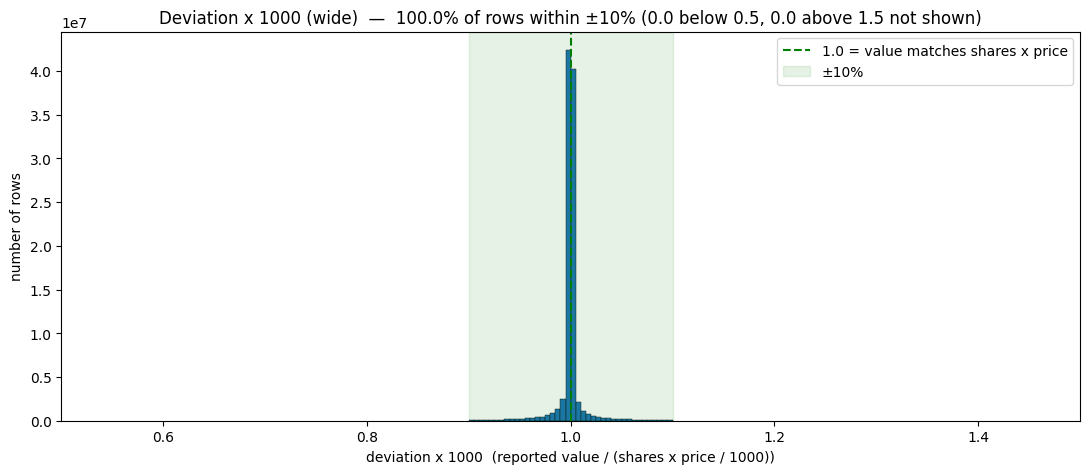

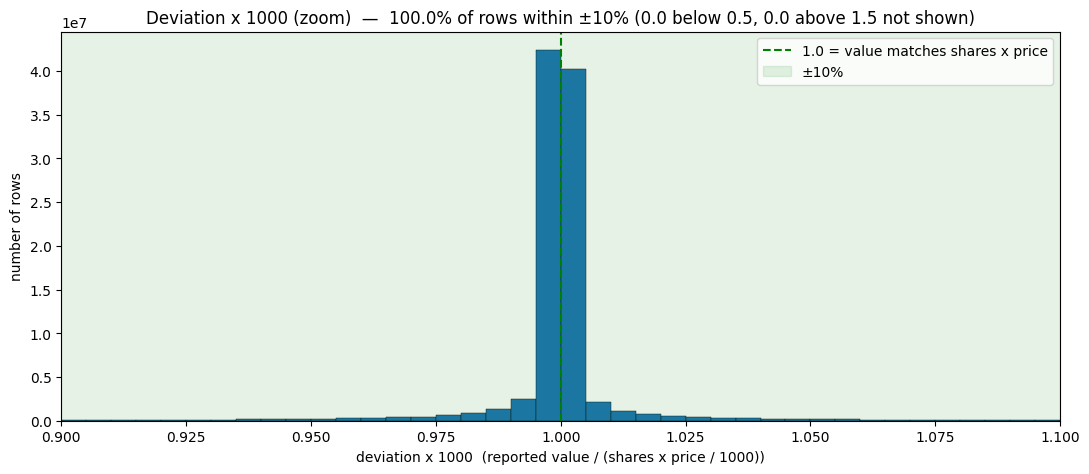

In [14]:
import matplotlib.pyplot as plt

dev = p.stage("deviation_check")

# Collected once at the fine bin width; the wide and the zoomed plot reuse the same data.
LO, HI, BIN = 0.5, 1.5, 0.005    # deviation × 1000
TOL = dev_poss_diff              # same tolerance as the fixing / delete steps

dev_hist = dev.run("deviation_histogram", f"""
    WITH d AS (SELECT deviation * 1000 AS r FROM {CLEAN_TABLE} WHERE deviation IS NOT NULL)
    SELECT floor(r / {BIN}) * {BIN} AS bin, count(*) AS n
    FROM d
    WHERE r >= {LO} AND r < {HI}
    GROUP BY 1
    ORDER BY 1;
""", note=f"bins of {BIN} in [{LO}, {HI})").astype(float)

dev_summary = dev.run("deviation_summary", f"""
    WITH d AS (SELECT deviation * 1000 AS r FROM {CLEAN_TABLE})
    SELECT count(*)                                         AS total,
           count(*) FILTER (WHERE r IS NULL)                AS deviation_null,
           count(*) FILTER (WHERE abs(r - 1) <= {TOL})      AS within_tol,
           count(*) FILTER (WHERE r < {LO})                 AS below_range,
           count(*) FILTER (WHERE r >= {HI})                AS above_range,
           percentile_cont(0.5) WITHIN GROUP (ORDER BY r)   AS median_ratio
    FROM d;
""", note=f"within_tol = |deviation x 1000 - 1| <= {TOL}")

s = dev_summary.iloc[0]
for name, (xlo, xhi) in {"wide": (LO, HI), "zoom": (1 - TOL, 1 + TOL)}.items():
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(dev_hist["bin"], dev_hist["n"], width=BIN, align="edge", edgecolor="black", linewidth=0.3)
    ax.axvline(1.0, color="green", linestyle="--", label="1.0 = value matches shares x price")
    ax.axvspan(1 - TOL, 1 + TOL, color="green", alpha=0.1, label=f"±{TOL:.0%}")
    ax.set_title(f"Deviation x 1000 ({name})  —  {s.within_tol / s.total:.1%} of rows within ±{TOL:.0%} "
                 f"({s.below_range:,} below {LO}, {s.above_range:,} above {HI} not shown)")
    ax.set_xlabel("deviation x 1000  (reported value / (shares x price / 1000))")
    ax.set_ylabel("number of rows")
    ax.set_xlim(xlo, xhi)
    ax.legend()
    plt.tight_layout()
    fig.savefig(p.log_dir / f"deviation_histogram_{name}.png", dpi=150)
    plt.show()

## 5. Ownership

`ownership = shares / (shrout × 1000)` (`shrout` is in thousands).

### 5.1 More shares than outstanding

In [15]:
own = p.stage("ownership")

own.run("delete_shares_over_outstanding", f"""
    DELETE FROM {CLEAN_TABLE}
        WHERE shares/1000 > shrout;
""")

✅ **[ownership] delete_shares_over_outstanding**: `ok` | `DELETE 3264` | rows: **3,264** | 89.4s

""


### 5.2 Ownership distribution

Also computes the lower cut-off percentile `OWN_LOW_Q` used in 5.3, and the `OWN_HIGH_Q` percentile for reference
only (EDGAR-Parsing's upper cut-off, not applied here, see 5.3).

✅ **[ownership] ownership_histogram**: `ok` | `SELECT 161` | rows: **161** | 103.0s

> log10(%) bins of 0.05 in [-6, 3)

,bin,n
0,-6.00,4412
1,-5.95,4957
2,-5.90,5500
3,-5.85,6318
4,-5.80,7453
...,...,...
156,1.80,2609
157,1.85,2276
158,1.90,2126
159,1.95,2173


✅ **[ownership] ownership_summary**: `ok` | `SELECT 1` | rows: **1** | 237.4s

> low_cut_pct = 0.05% percentile, used by the delete below; high_cut_pct = 99.95% percentile, reference only

,total,over_100pct,over_5pct,below_range,above_range,median_pct,low_cut_pct,high_cut_pct,no_shrout
0,97863663,0,1000121,22895,0,0.018227,0.000002,24.698372,0


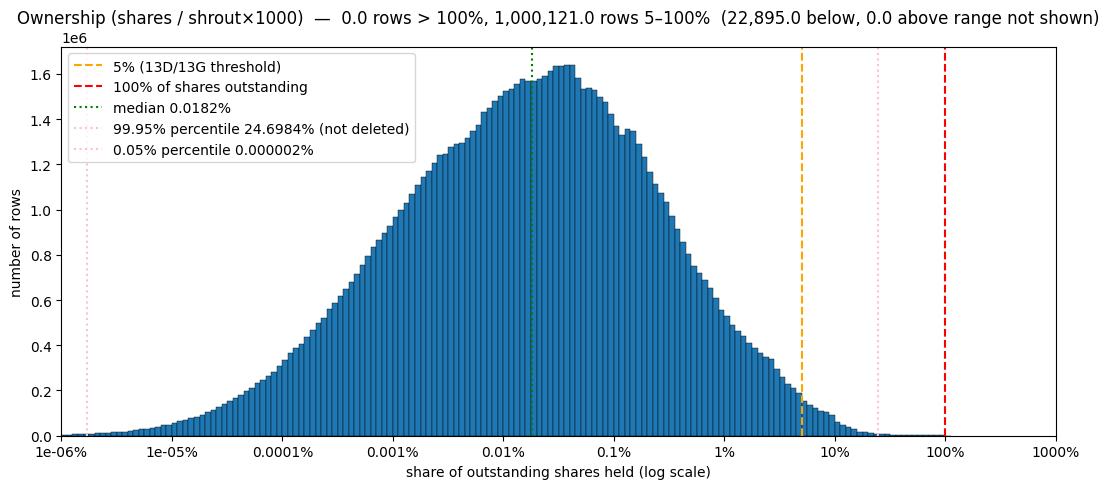

In [16]:
import numpy as np
import matplotlib.pyplot as plt

own = p.stage("ownership")

# ownership % = shares / (shrout * 1000) * 100   (shrout is in thousands)
# Holdings span many orders of magnitude, so bins are in log10(%).
LO, HI, BIN = -6, 3, 0.05            # log10(%) range: 0.000001% … 1000%, bin width
OWN_LOW_Q  = 0.0005   # rows below this percentile are deleted in 5.3
OWN_HIGH_Q = 0.9995   # reference only (EDGAR-Parsing's upper cut-off), not deleted

pct_cte = f"""
    WITH d AS (
        SELECT shares::float8 / (shrout::float8 * 1000) * 100 AS pct
        FROM {CLEAN_TABLE}
        WHERE shares > 0 AND shrout > 0
    )"""

own_hist = own.run("ownership_histogram", f"""
    {pct_cte}
    SELECT floor(log(pct) / {BIN}) * {BIN} AS bin, count(*) AS n
    FROM d
    WHERE pct >= POWER(10, {LO}) AND pct < POWER(10, {HI})
    GROUP BY 1
    ORDER BY 1;
""", note=f"log10(%) bins of {BIN} in [{LO}, {HI})").astype(float)

own_summary = own.run("ownership_summary", f"""
    {pct_cte}
    SELECT count(*)                                                  AS total,
           count(*) FILTER (WHERE pct > 100)                         AS over_100pct,
           count(*) FILTER (WHERE pct > 5 AND pct <= 100)            AS over_5pct,
           count(*) FILTER (WHERE pct < POWER(10, {LO}))             AS below_range,
           count(*) FILTER (WHERE pct >= POWER(10, {HI}))            AS above_range,
           percentile_cont(0.5)          WITHIN GROUP (ORDER BY pct) AS median_pct,
           percentile_cont({OWN_LOW_Q})  WITHIN GROUP (ORDER BY pct) AS low_cut_pct,
           percentile_cont({OWN_HIGH_Q}) WITHIN GROUP (ORDER BY pct) AS high_cut_pct,
           (SELECT count(*) FROM {CLEAN_TABLE}
             WHERE shrout IS NULL OR shrout <= 0)                    AS no_shrout
    FROM d;
""", note=f"low_cut_pct = {OWN_LOW_Q:.2%} percentile, used by the delete below; high_cut_pct = {OWN_HIGH_Q:.2%} percentile, reference only")

s = own_summary.iloc[0]
OWN_LOW_CUT, OWN_HIGH_CUT = float(s.low_cut_pct), float(s.high_cut_pct)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(own_hist["bin"], own_hist["n"], width=BIN, align="edge", edgecolor="black", linewidth=0.3)

ax.axvline(np.log10(5),   color="orange", linestyle="--", label="5% (13D/13G threshold)")
ax.axvline(np.log10(100), color="red",    linestyle="--", label="100% of shares outstanding")
ax.axvline(np.log10(s.median_pct), color="green", linestyle=":", label=f"median {s.median_pct:.4f}%")
ax.axvline(np.log10(OWN_HIGH_CUT), color="pink", linestyle=":", label=f"{OWN_HIGH_Q:.2%} percentile {OWN_HIGH_CUT:.4f}% (not deleted)")
ax.axvline(np.log10(OWN_LOW_CUT),  color="pink", linestyle=":", label=f"{OWN_LOW_Q:.2%} percentile {OWN_LOW_CUT:.6f}%")

ticks = np.arange(LO, HI + 1)
ax.set_xticks(ticks, [f"{10.0**t:g}%" for t in ticks])
ax.set_title(f"Ownership (shares / shrout×1000)  —  {s.over_100pct:,} rows > 100%, "
             f"{s.over_5pct:,} rows 5–100%  ({s.below_range:,} below, {s.above_range:,} above range not shown)")
ax.set_xlabel("share of outstanding shares held (log scale)")
ax.set_ylabel("number of rows")
ax.set_xlim(LO, HI)
ax.legend()
plt.tight_layout()
fig.savefig(p.log_dir / "ownership_histogram.png", dpi=150)
plt.show()

### 5.3 Remove ownership outliers

Only the lower cut-off from 5.2 is applied: positions below the `OWN_LOW_Q` percentile (a few shares of a large
company) are removed as reporting artefacts.

There is **no upper percentile cut**. Impossible stakes (> 100% of the shares outstanding) are already removed in
5.1, and the stakes above the 99.95% percentile (about 25% of a company) are real large holdings: parent companies,
founders' vehicles, activists. In the graph an edge weight is the share of the owner's portfolio, so these
holdings do not distort the weights, and removing them would delete real edges. (EDGAR-Parsing applies a 99.95%
cut-off computed on the XML reports; `OWN_HIGH_CUT` in 5.2 shows where it would fall here.)

In [17]:
own.run("delete_ownership_outliers", f"""
    DELETE FROM {CLEAN_TABLE}
        WHERE shares::float8 / (shrout::float8 * 1000) * 100 < {OWN_LOW_CUT!r};
""", note=f"cut-off from ownership_summary: {OWN_LOW_Q:.2%} percentile; no upper cut (see above)")

✅ **[ownership] delete_ownership_outliers**: `ok` | `DELETE 48932` | rows: **48,932** | 90.8s

> cut-off from ownership_summary: 0.05% percentile; no upper cut (see above)

""


## 6. Finalise

Indexes on `cik`, `cusip9`, `rdate`; `VACUUM` reclaims the space left by the deletes and updates,
`ANALYZE` refreshes the planner statistics. After this section the holdings table is ready to use.

In [18]:
final = p.stage("clean_final")

final.run("idx_clean_cik",    f"CREATE INDEX IF NOT EXISTS idx_holdings_cik    ON {CLEAN_TABLE} (cik);")
final.run("idx_clean_cusip9", f"CREATE INDEX IF NOT EXISTS idx_holdings_cusip9 ON {CLEAN_TABLE} (cusip9);")
final.run("idx_clean_rdate",  f"CREATE INDEX IF NOT EXISTS idx_holdings_rdate  ON {CLEAN_TABLE} (rdate);")
final.run("vacuum_analyze_clean", f"VACUUM (ANALYZE) {CLEAN_TABLE};")

✅ **[clean_final] idx_clean_cik**: `ok` | `CREATE INDEX` | 142.3s

✅ **[clean_final] idx_clean_cusip9**: `ok` | `CREATE INDEX` | 178.7s

✅ **[clean_final] idx_clean_rdate**: `ok` | `CREATE INDEX` | 126.0s

✅ **[clean_final] vacuum_analyze_clean**: `ok` | `VACUUM` | 593.1s

""


In [19]:
final.row_estimate(CLEAN_TABLE, "clean_final")
final.table_size(CLEAN_TABLE, "clean_final")

✅ **[clean_final] clean_final_count_estimate**: `ok` | `SELECT 1` | rows: **1** | 0.0s

,estimate
0,97681472


✅ **[clean_final] clean_final_size**: `ok` | `SELECT 1` | rows: **1** | 0.0s

,total,heap,indexes
0,25 GB,22 GB,2988 MB


,total,heap,indexes
0,25 GB,22 GB,2988 MB


## 7. Run log analytics

Reads `steps.jsonl` from **all** runs in `logs/holdings/`.

In [20]:
logs = load_logs(LOG_ROOT)
steps_table(logs, p.run_id)

,seq,phase,step,status,statusmessage,rowcount,expected,diff,duration_s
343,1,value_fix,value_dollars_to_thousands,ok,UPDATE 0,0.0,NaN,NaN,76.449
344,2,value_fix,sh_prn_counts_before,ok,SELECT 3,3.0,NaN,NaN,72.361
345,3,value_fix,reclassify_prn_as_sh,ok,UPDATE 91686,91686.0,NaN,NaN,80.599
346,4,value_fix,reclassify_null_as_sh,ok,UPDATE 8072860,8072860.0,NaN,NaN,205.150
347,5,value_fix,sh_prn_counts_after,ok,SELECT 3,3.0,NaN,NaN,122.820
348,6,value_fix,delete_not_sh,ok,DELETE 400329,400329.0,NaN,NaN,95.704
349,7,value_fix,delete_deviation_null,ok,DELETE 0,0.0,NaN,NaN,79.788
350,8,value_fix,delete_deviation_outside_tolerance,ok,DELETE 3148198,3148198.0,NaN,NaN,288.860
351,9,deviation_check,deviation_histogram,ok,SELECT 40,40.0,NaN,NaN,349.431
352,10,deviation_check,deviation_summary,ok,SELECT 1,1.0,NaN,NaN,139.455


In [21]:
# Row counts that differ from the previous run (Status.md)
expected_mismatches(logs, p.run_id)

,seq,phase,step,status,statusmessage,rowcount,expected,diff,duration_s


In [22]:
phase_durations(logs, p.run_id)

,seconds
phase,
value_fix,1021.731
deviation_check,488.886
ownership,520.638
clean_final,1040.085


In [23]:
compare_runs(logs)

rowcount                                                                                                                                  \
run_id                                 20261007_141134 20261007_142656 20261007_145504 20261007_191644 20261008_121632 20261008_175800 20261008_175818 20261008_180312 20261029_121251   
phase       step                                                                                                                                                                         
setup_pre   drop_input_table                      -1.0             NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN   
            create_input_table                    -1.0             NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN   
            create_cusip_check_digit              -1.0             NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN   
load        load_holdings_py                       NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN   
            after_load_tracking_status             NaN        308593.0             NaN             NaN             NaN             NaN             NaN             NaN             NaN   
...                                                ...             ...             ...             ...             ...             ...             ...             ...             ...   
clean_final idx_clean_cusip9                       NaN             NaN             NaN             NaN             NaN             NaN             NaN            -1.0             NaN   
            idx_clean_rdate                        NaN             NaN             NaN             NaN             NaN             NaN             NaN            -1.0             NaN   
            vacuum_analyze_clean                   NaN             NaN             NaN             NaN             NaN             NaN             NaN            -1.0             NaN   
            clean_final_count_estimate             NaN             NaN             NaN             NaN             NaN             NaN             NaN             1.0             NaN   
            clean_final_size                       NaN             NaN             NaN             NaN             NaN             NaN             NaN             1.0             NaN   

                                                            duration_s                                                                                                                  \
run_id                                 20261029_150051 20261007_132141 20261007_141134 20261007_142656 20261007_145142 20261007_145504 20261007_191644 20261008_121632 20261008_175800   
phase       step                                                                                                                                                                         
setup_pre   drop_input_table                       NaN             NaN           0.034             NaN             NaN             NaN             NaN             NaN             NaN   
            create_input_table                     NaN             NaN           0.013             NaN             NaN             NaN             NaN             NaN             NaN   
            create_cusip_check_digit               NaN             NaN           0.006             NaN             NaN             NaN             NaN             NaN             NaN   
load        load_holdings_py                       NaN             NaN             NaN        1236.408             NaN             NaN             NaN             NaN             NaN   
            after_load_tracking_status             NaN             NaN             NaN             NaN             NaN             NaN     

In [24]:
p.close()

Run log: <THESIS_DIR>/src/Clean_solution/Database/Initialisation/logs/holdings/20261029_150051/steps.jsonl


### Deletes on the clean table

Every `DELETE` on the clean table in this run with rows deleted and rows left. Reads the logs only, so it works after `p.close()`.

In [29]:
import re

logs = load_logs(LOG_ROOT)
run = logs[logs["run_id"] == p.run_id].sort_values("seq")
ok = run[run["status"] == "ok"]

start = ok[ok["step"] == "insert_clean"].iloc[-1]
deletes = ok[(ok["seq"] > start["seq"]) &
             ok["sql"].fillna("").str.contains(rf"DELETE\s+FROM\s+{re.escape(CLEAN_TABLE)}",
                                               case=False, regex=True)].copy()

deletes["condition"] = (deletes["sql"].str.replace(r"\s+", " ", regex=True)
                                      .str.extract(r"WHERE (.*?);?$", flags=re.I)[0])
deletes["rows_deleted"] = deletes["rowcount"].astype(int)
deletes["rows_left"] = int(start["rowcount"]) - deletes["rows_deleted"].cumsum()

print(f"inserted: {int(start['rowcount']):,}  |  deleted: {deletes['rows_deleted'].sum():,}  "
      f"|  left: {deletes['rows_left'].iloc[-1]:,}")
deletes[["seq", "phase", "step", "condition", "rows_deleted", "rows_left"]]


inserted: 118,619,185  |  deleted: 20,804,454  |  left: 97,814,731


,seq,phase,step,condition,rows_deleted,rows_left
327,32,clean_create,delete_options,put_call IS NOT NULL,5288383,113330802
328,33,filings,delete_notice_filings,"form IN ('13F-NT', '13F-NT/A')",383892,112946910
341,46,filings,delete_flagged_filings,f.to_delete AND h.cik = f.cik AND h.rdate = f....,11531456,101415454
348,53,value_fix,delete_not_sh,shrs_or_prn_amt IS NULL OR shrs_or_prn_amt='PRN',400329,101015125
349,54,value_fix,delete_deviation_null,deviation IS NULL,0,101015125
350,55,value_fix,delete_deviation_outside_tolerance,ABS(deviation - 0.001) >= 0.0001,3148198,97866927
353,58,ownership,delete_shares_over_outstanding,shares/1000 > shrout,3264,97863663
356,61,ownership,delete_ownership_outliers,shares::float8 / (shrout::float8 * 1000) * 100...,48932,97814731
